In [33]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn import preprocessing
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.metrics import silhouette_score


In [34]:
print(os.getcwd())

/home/gca21/master/data-engineering/Proyecto-Ingenieria-Dato/Notebooks


In [35]:
PATH = os.getcwd() + "/../src/data/HU4_EDA.csv"
df = pd.read_csv(PATH)

In [36]:
df.head()

,nombre,dosis (mg),estado_aut,estado_rev,comercializado,generico,afecta_conduccion,num_principios_activos,Volumen_Informativo,Complejidad_Desglose,...,labtitular_infrequent_sklearn,labcomercializador_infrequent_sklearn,forma_farmaceutica_simplificada_COMPRIMIDO,forma_farmaceutica_simplificada_infrequent_sklearn,vias_administracion_VÍA ORAL,vias_administracion_infrequent_sklearn,Estado_ALTA,Estado_infrequent_sklearn,Tratamiento de larga duración_NO,Tratamiento de larga duración_infrequent_sklearn
0,"ALMOTRIPTAN CINFA 12,5 MG COMPRIMIDOS RECUBIER...",12.5,2014,2014,1,1,1,1,636,1,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,"ALMOTRIPTAN NORMON 12,5 MG COMPRIMIDOS RECUBIE...",12.5,2013,2013,1,1,1,1,662,1,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,"ALMOTRIPTAN STADA 12,5 MG COMPRIMIDOS RECUBIER...",12.5,2014,2014,1,1,1,1,650,1,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,IBUPROFENO (ARGININA) KERN PHARMA 600 mg GRANU...,600.0,2008,2008,1,1,0,1,1375,0,...,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
4,IBUPROFENO STADA 600 MG COMPRIMIDOS RECUBIERTO...,600.0,2013,2013,1,1,0,1,1238,0,...,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [37]:
df.dtypes

nombre                                                    str
dosis (mg)                                            float64
estado_aut                                              int64
estado_rev                                              int64
comercializado                                          int64
generico                                                int64
afecta_conduccion                                       int64
num_principios_activos                                  int64
Volumen_Informativo                                     int64
Complejidad_Desglose                                    int64
Indicador_Riesgo                                        int64
Precio venta al público con IVA                       float64
pactivos_infrequent_sklearn                           float64
labtitular_infrequent_sklearn                         float64
labcomercializador_infrequent_sklearn                 float64
forma_farmaceutica_simplificada_COMPRIMIDO            float64
forma_fa

In [38]:
df.drop(columns="nombre", inplace=True)
df.dtypes

dosis (mg)                                            float64
estado_aut                                              int64
estado_rev                                              int64
comercializado                                          int64
generico                                                int64
afecta_conduccion                                       int64
num_principios_activos                                  int64
Volumen_Informativo                                     int64
Complejidad_Desglose                                    int64
Indicador_Riesgo                                        int64
Precio venta al público con IVA                       float64
pactivos_infrequent_sklearn                           float64
labtitular_infrequent_sklearn                         float64
labcomercializador_infrequent_sklearn                 float64
forma_farmaceutica_simplificada_COMPRIMIDO            float64
forma_farmaceutica_simplificada_infrequent_sklearn    float64
vias_adm

In [39]:
X = df.values

<Axes: >

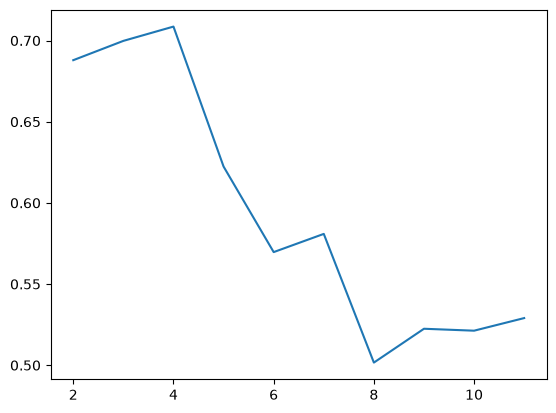

In [44]:
X_norm = preprocessing.normalize(X)


K = range(2, 12)
fits = []
score = []


for k in K:
    # train the model for current value of k on training data
    model = KMeans(n_clusters = k, random_state = 42, n_init='auto').fit(X_norm)
    
    # append the model to fits
    fits.append(model)
    
    # Append the silhouette score to scores
    score.append(silhouette_score(X_norm, model.labels_, metric='euclidean'))

sns.lineplot(x = K, y = score)

Observamos que con 8 clústeres se obtiene la menor distancia media a los vecinos, por lo que trabajermos con ese número de clústeres y evaluaremos los resultados

In [45]:
model = KMeans(n_clusters = 8, random_state = 42, n_init='auto').fit(X_norm)

Debido al gran número de columnas que tenemos, evaluar los resultados visualmente es complejo. Para facilitar el análisis, se reducen los datos a un espacio de 2 dimensiones, representando los datos con 2 componentes que expliquen la mayoría de la variabilidad de los datos.

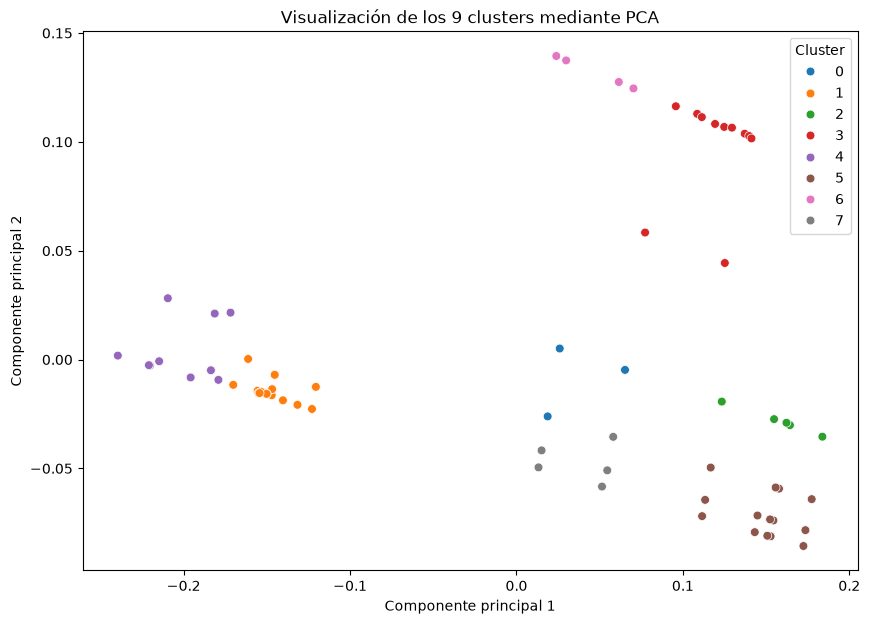

In [46]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_norm)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=model.labels_,
    palette='tab10',
    s=40
)

plt.title('Visualización de los 9 clusters mediante PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.legend(title='Cluster')

plt.show()